<a href="https://colab.research.google.com/github/Nemmoxida/Data-Science/blob/main/Data_Sci_5_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Impor Dataset, Periksa Dimensi Awal, dan Informasi Tipe Data

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
# Load dataset
df = pd.read_csv('/content/nasabah_raw.csv')

# 1. Periksa dimensi awal dan informasi tipe data
print("=== Dimensi Awal Dataset")
print(df.shape)

print("\nInformasi Tipe Data Tiap Kolom")
df.info()

=== Dimensi Awal Dataset
(1045, 9)

Informasi Tipe Data Tiap Kolom
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB


### 2. Identifikasi, Tampilkan Sampel Duplikat, dan Hapus Duplikat

In [ ]:
# 2 Identifikasi jumlah data duplikat penuh
duplicate_mask = df.duplicated(keep=False)
num_duplicates = df.duplicated().sum()
print(f"Jumlah baris duplikat penuh: {num_duplicates}")

if num_duplicates > 0:
    print("\nSampel Baris yang Terduplikasi")
    display(df[duplicate_mask].sort_values(by=list(df.columns)).head(10))
else:
    print("\nTidak ada baris yang terduplikasi.")

# Hapus duplikat
df_cleaned = df.drop_duplicates()

Jumlah baris duplikat penuh: 45

Sampel Baris yang Terduplikasi


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
59,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
1039,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
76,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
1011,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
96,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
1041,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
101,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
1026,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
136,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN
1009,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN



Duplikat telah berhasil dihapus.


### 3. Sisa Baris Data Setelah Penghapusan Duplikat

In [ ]:
# 3 sisa baris data
print(f"Sisa baris data setelah penghapusan duplikat: {df_cleaned.shape[0]} baris")

Sisa baris data setelah penghapusan duplikat: 1000 baris


### 4. Pembersihan Nilai Unik Kolom Status_Pernikahan

In [ ]:
# Tampilkan nilai unik sebelum dibersihkan
print("Nilai unik sebelum pembersihan:")
print(df_cleaned['Status_Pernikahan'].unique())

# Strip whitespace dan ubah menjadi Title Case / Kapital
df_cleaned['Status_Pernikahan'] = df_cleaned['Status_Pernikahan'].astype(str).str.strip().str.title()

# Tampilkan nilai unik setelah dibersihkan
print("\nNilai unik setelah pembersihan:")
print(df_cleaned['Status_Pernikahan'].unique())

Nilai unik sebelum pembersihan:
['Menikah' 'Single' 'single' 'Cerai' ' MENIKAH ']

Nilai unik setelah pembersihan:
['Menikah' 'Single' 'Cerai']


/tmp/ipykernel_5834/3040635807.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned['Status_Pernikahan'] = df_cleaned['Status_Pernikahan'].astype(str).str.strip().str.title()


### 5. Pemeriksaan Logis Kolom Usia (Menangani Outliers)

In [ ]:

# Tampilkan statistik deskriptif awal untuk Usia
print("Statistik Usia sebelum koreksi:")
print(df_cleaned['Usia'].describe())

# Tentukan ambang batas valid
min_valid_age = 17
max_valid_age = 100

# Identifikasi jumlah data yang melanggar batas logis
outliers_count = ((df_cleaned['Usia'] < min_valid_age) | (df_cleaned['Usia'] > max_valid_age)).sum()
print(f"\nJumlah baris dengan usia tidak logis: {outliers_count}")

# Ubah nilai yang melanggar batas menjadi NaN
df_cleaned.loc[(df_cleaned['Usia'] < min_valid_age) | (df_cleaned['Usia'] > max_valid_age), 'Usia'] = np.nan

# Tampilkan statistik deskriptif setelah koreksi
print("\nStatistik Usia setelah koreksi (di luar 17-100 tahun diubah ke NaN):")
print(df_cleaned['Usia'].describe())

Statistik Usia sebelum koreksi:
count    1000.000000
mean       42.022000
std        33.802605
min        -5.000000
25%        29.000000
50%        41.000000
75%        51.000000
max       350.000000
Name: Usia, dtype: float64

Jumlah baris dengan usia tidak logis: 35

Statistik Usia setelah koreksi (di luar 17-100 tahun diubah ke NaN):
count    965.000000
mean      40.048705
std       11.787130
min       20.000000
25%       30.000000
50%       41.000000
75%       50.000000
max       59.000000
Name: Usia, dtype: float64


### 6. Analisis Logis Koreksi Nilai Sebelum Imputasi

**Mengapa koreksi kesalahan nilai pada Usia harus dilakukan sebelum menghitung nilai rata-rata (mean) atau median?**

Koreksi kesalahan nilai (seperti mengubah usia tidak logis seperti `-5` atau `200` tahun menjadi `NaN`) harus dilakukan terlebih dahulu karena:
1. **Menghindari Bias Statistik:** Nilai ekstrem/tidak logis (*outliers* ekstrem atau *noise*) akan sangat memengaruhi perhitungan rata-rata (*mean*). Jika nilai salah tersebut diikutkan, nilai rata-rata yang diperoleh menjadi tidak representatif bagi mayoritas populasi sesungguhnya.
2. **Menjaga Akurasi Imputasi:** Jika kita langsung melakukan imputasi atau pengisian nilai kosong menggunakan nilai *mean* atau *median* yang belum terkoreksi, maka nilai pengganti tersebut akan ikut bias (terdistorsi oleh data sampah). Proses pembersihan di awal memastikan nilai agregat yang digunakan untuk pengisian data kosong adalah nilai yang objektif dan valid.

### 7, 8, & 9. Penggabungan Data dengan data_kredit_eksternal.csv (Left Join)

In [ ]:
# Load data kredit eksternal
df_kredit_eksternal = pd.read_csv('/content/data_kredit_eksternal.csv')

# Lakukan left join berdasarkan kunci ID_Pelanggan
df_merged = pd.merge(df_cleaned, df_kredit_eksternal, on='ID_Pelanggan', how='left')

# Tampilkan dimensi dataset setelah proses penggabungan
print("Dimensi Dataset Setelah Penggabungan")
print(df_merged.shape)

Dimensi Dataset Setelah Penggabungan
(1000, 11)


### 10. Persentase Missing Values Sebelum Imputasi

In [ ]:
# 10. Tampilkan persentase missing values untuk setiap kolom
missing_percentage = (df_merged.isnull().sum() / len(df_merged)) * 100
print("Persentase Missing Values per Kolo")
print(missing_percentage)

Persentase Missing Values per Kolo
ID_Pelanggan                0.0
Usia                        3.5
Pendapatan_Bulanan          6.0
Skor_Kredit                 0.0
Lama_Bekerja_Thn            4.0
Status_Pernikahan           0.0
Tingkat_Pendidikan          3.5
Status_Default              0.0
Pendapatan_Tahunan_Est      6.0
Pernah_Gagal_Bayar_Lain    15.0
Jumlah_Kartu_Kredit        15.0
dtype: float64


### 11 & 12. Imputasi dan Verifikasi Akhir Missing Values

In [ ]:
# 11. Tangani missing value dengan strategi yang ditentukan

# Kolom numerik kontinu: Median
for col in ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn', 'Pendapatan_Tahunan_Est']:
    median_val = df_merged[col].median()
    df_merged[col] = df_merged[col].fillna(median_val)

# Kolom diskrit: 0
df_merged['Jumlah_Kartu_Kredit'] = df_merged['Jumlah_Kartu_Kredit'].fillna(0)

# Kolom kategorikal: Modus
for col in ['Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']:
    mode_val = df_merged[col].mode()[0]
    df_merged[col] = df_merged[col].fillna(mode_val)

# 12. Pastikan tidak ada lagi missing value yang tersisa
missing_after = df_merged.isnull().sum()
print("Jumlah Missing Values Setelah Imputasi")
print(missing_after)
print(f"\nTotal Missing Values tersisa: {missing_after.sum()}")

Jumlah Missing Values Setelah Imputasi
ID_Pelanggan               0
Usia                       0
Pendapatan_Bulanan         0
Skor_Kredit                0
Lama_Bekerja_Thn           0
Status_Pernikahan          0
Tingkat_Pendidikan         0
Status_Default             0
Pendapatan_Tahunan_Est     0
Pernah_Gagal_Bayar_Lain    0
Jumlah_Kartu_Kredit        0
dtype: int64

Total Missing Values tersisa: 0


### 13. Visualisasi Box Plot Pendapatan Bulanan

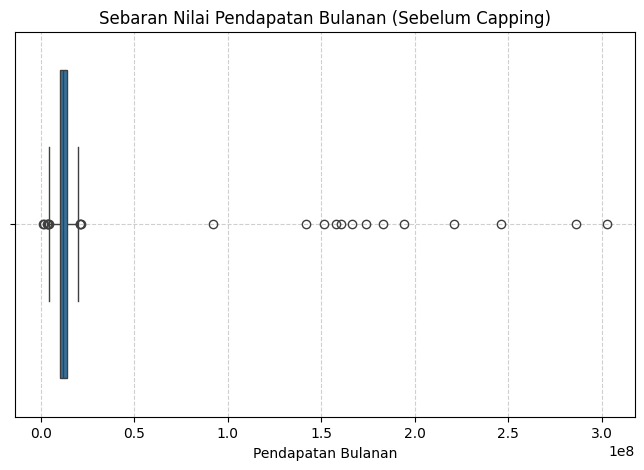

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 13. Visualisasi box plot sebelum penanganan outlier
plt.figure(figsize=(8, 5))
sns.boxplot(x=df_merged['Pendapatan_Bulanan'])
plt.title('Sebaran Nilai Pendapatan Bulanan (Sebelum Capping)')
plt.xlabel('Pendapatan Bulanan')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 14 & 15. Menghitung Batas IQR dan Menerapkan Capping (Pembatasan Nilai Ekstrem)

Q1: 10192000.0
Q3: 14100250.0
IQR: 3908250.0
Batas Bawah: 4329625.0
Batas Atas: 19962625.0


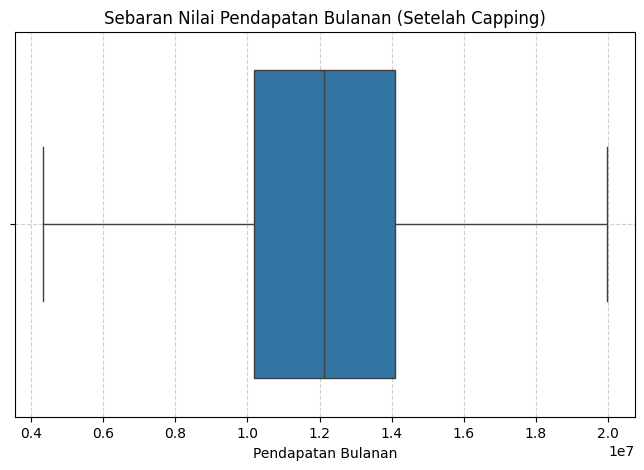

In [ ]:
# 14. Hitung ambang batas menggunakan metode IQR
Q1 = df_merged['Pendapatan_Bulanan'].quantile(0.25)
Q3 = df_merged['Pendapatan_Bulanan'].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Batas Bawah: {batas_bawah}")
print(f"Batas Atas: {batas_atas}")

# 15. Terapkan metode pembatasan nilai (capping) tanpa membuang baris
df_merged['Pendapatan_Bulanan'] = df_merged['Pendapatan_Bulanan'].clip(lower=batas_bawah, upper=batas_atas)

# Visualisasi kembali setelah penanganan outlier
plt.figure(figsize=(8, 5))
sns.boxplot(x=df_merged['Pendapatan_Bulanan'])
plt.title('Sebaran Nilai Pendapatan Bulanan (Setelah Capping)')
plt.xlabel('Pendapatan Bulanan')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 16. Analisis Konsekuensi Membuang Baris Outlier

**Apa konsekuensi negatif jika Anda memilih membuang baris (drop rows) yang mengandung outlier dibandingkan melakukan pembatasan (capping) pada dataset ini?**

1. **Kehilangan Informasi Berharga (Loss of Data/Information):** Outlier pada kolom keuangan seperti pendapatan sering kali merupakan representasi dari nasabah riil yang memang memiliki profil pendapatan sangat tinggi (misal nasabah premium/HNWI). Membuang baris ini berarti kita kehilangan seluruh informasi profil nasabah tersebut.
2. **Pengurangan Ukuran Sampel secara Signifikan:** Menghapus baris akan mengurangi ukuran dataset secara drastis, sehingga mengurangi kekuatan statistik (*statistical power*) dari analisis atau model machine learning yang akan dibangun.
3. **Bias Seleksi (Selection Bias):** Model yang dibuat nantinya hanya akan mengenali nasabah dengan pendapatan "normal", sehingga gagal membuat prediksi yang akurat ketika menghadapi calon nasabah baru dengan profil pendapatan tinggi/tidak biasa di masa depan.

### 17, 18, 19 & 20. Feature Encoding & Pembersihan Kolom

In [ ]:
# Buat salinan dataframe untuk pemodelan
df_encoded = df_merged.copy()

# 17. Ordinal Encoding pada Tingkat_Pendidikan
pendidikan_mapping = {'SMA': 1, 'Sarjana': 2, 'Magister': 3}
df_encoded['Tingkat_Pendidikan'] = df_encoded['Tingkat_Pendidikan'].map(pendidikan_mapping)

# 18. Binary Mapping pada Pernah_Gagal_Bayar_Lain
gagal_bayar_mapping = {'Tidak': 0, 'Ya': 1}
df_encoded['Pernah_Gagal_Bayar_Lain'] = df_encoded['Pernah_Gagal_Bayar_Lain'].map(gagal_bayar_mapping)

# 19. One-Hot Encoding pada Status_Pernikahan dengan drop_first=True
df_encoded = pd.get_dummies(df_encoded, columns=['Status_Pernikahan'], drop_first=True, dtype=int)

# 20. Hapus kolom identifier (ID_Pelanggan) yang tidak diperlukan untuk pemodelan
df_encoded = df_encoded.drop(columns=['ID_Pelanggan'])

display(df_encoded.head())

,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,58.0,10118000.0,542.0,13.0,3,0,121416000.0,0,5.0,1,0
1,48.0,10514000.0,331.0,20.0,2,0,126168000.0,0,3.0,1,0
2,34.0,13257000.0,690.0,22.0,3,0,159084000.0,0,5.0,1,0
3,27.0,10832000.0,576.0,7.0,2,0,129984000.0,1,6.0,1,0
4,41.0,8295000.0,831.0,15.0,1,0,99540000.0,1,4.0,0,1


### 21, 22 & 23. Pemisahan Fitur, Standarisasi (Z-score), dan Verifikasi Statistik

In [ ]:
from sklearn.preprocessing import StandardScaler

# 21. Pisahkan fitur prediktor (X) dan target (y = Status_Default)
X = df_encoded.drop(columns=['Status_Default'])
y = df_encoded['Status_Default']

numerical_cols = ['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit']

print("Statistik Deskriptif Sebelum Standarisasi")
display(X[numerical_cols].describe())

# 22. Lakukan transformasi Standardization (Z-score)
scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[numerical_cols] = scaler.fit_transform(X[numerical_cols])

# 23. Tampilkan ringkasan statistik setelah standarisasi
print("\nStatistik Deskriptif Setelah Standarisasi")
display(X_scaled[numerical_cols].describe())

Statistik Deskriptif Sebelum Standarisasi


,Usia,Pendapatan_Bulanan,Skor_Kredit
count,1000.000000,1.000000e+03,1000.000000
mean,40.082000,1.212750e+07,580.507000
std,11.580128,3.062611e+06,158.990729
min,20.000000,4.329625e+06,300.000000
25%,30.000000,1.019200e+07,440.750000
50%,41.000000,1.213200e+07,579.000000
75%,50.000000,1.410025e+07,722.250000
max,59.000000,1.996262e+07,849.000000



Statistik Deskriptif Setelah Standarisasi


,Usia,Pendapatan_Bulanan,Skor_Kredit
count,1.000000e+03,1.000000e+03,1.000000e+03
mean,-7.105427e-17,3.552714e-18,3.232969e-16
std,1.000500e+00,1.000500e+00,1.000500e+00
min,-1.735045e+00,-2.547425e+00,-1.765181e+00
25%,-8.710650e-01,-6.322922e-01,-8.794659e-01
50%,7.931340e-02,1.471131e-03,-9.483283e-03
75%,8.568957e-01,6.444632e-01,8.919635e-01
max,1.634478e+00,2.559596e+00,1.689579e+00
